# Homework #2 - Sistemi Informativi Evoluti e Big Data (2025-2026)
## Analisi dei dati criminali di Los Angeles con InfluxDB e Python

Questo notebook risolve l'homework assegnato, coprendo i seguenti punti:
1.  **Caricamento e Preprocessing:** Pulizia dati, feature engineering e caricamento su InfluxDB[cite: 7].
2.  **Alerting System:** Simulazione di regole di allarme basate su soglie storiche[cite: 19].
3.  **Analisi Analitiche:** Query Flux per analizzare stagionalità, orari e crimini violenti[cite: 23].
4.  **Analisi Avanzata:** Clustering incrementale per individuare pattern di criminalità[cite: 33].

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time
from datetime import datetime

# Librerie InfluxDB
from influxdb_client import InfluxDBClient, Point, WriteOptions
from influxdb_client.client.write_api import SYNCHRONOUS

# Librerie per Clustering 
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')


### Configurazione

In [6]:

# Configurazione InfluxDB
url = "http://localhost:8086"
token = "W3cPRGkq7ds7JHFNtuciiVqEVPGugFye82mykiLWWee2FMxLDflsqsHk8OJaavTS9Sjh1_H31xU4yh3J5IC9RA=="
org = "unibs"
bucket = "crime_data"

client = InfluxDBClient(url=url, token=token, org=org)
write_api = client.write_api(write_options=WriteOptions(
    batch_size=5000, 
    flush_interval=1000)
    )
query_api = client.query_api()

## 1. Caricamento Dati e Preprocessing

In questa sezione carichiamo il CSV, puliamo i dati secondo le specifiche e arricchiamo il dataset con nuove feature (Stagione, Giorno/Notte).

**Requisiti soddisfatti:**
* Interpretazione record: DR_NO, Date Rptd, DATE OCC[cite: 8, 9, 10].
* Granularità giornaliera (ore 12:00:00)[cite: 11].
* Esclusione valori nulli e date future[cite: 22].

In [3]:
# Caricamento Dataset [cite: 4]
csv_path = "Crime_Data_from_2020_to_Present.csv"
df = pd.read_csv(csv_path)

# --- Data Cleaning ---
# Conversione date
# Il formato nel CSV è spesso '%m/%d/%Y %I:%M:%S %p' (es. 04/11/2021 12:00:00 AM)
df['DATE OCC'] = pd.to_datetime(df['DATE OCC'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')
df['Date Rptd'] = pd.to_datetime(df['Date Rptd'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce')

# Filtro dati validi
# 1. Coordinate non nulle
df = df[(df['LAT'] != 0) & (df['LON'] != 0)]

# 2. Date non future (oltre Nov 2025)
cutoff_date = pd.Timestamp('2025-11-30')
df = df[df['DATE OCC'] <= cutoff_date]

# 3. Tipi di crimine validi
df = df.dropna(subset=['Crm Cd'])

# --- Feature Engineering ---

# 1. Stagione
def get_season(date):
    month = date.month
    if month in [3, 4, 5]: return "Spring"
    elif month in [6, 7, 8]: return "Summer"
    elif month in [9, 10, 11]: return "Autumn"
    else: return "Winter"

# 2. Fascia Oraria (Day/Night)
def get_day_night(time_occ):
    # TIME OCC è un intero (es. 1430)
    hour = int(time_occ / 100)
    if 6 <= hour < 18:
        return "Day"
    else:
        return "Night"

# Stagione e Fascia Oraria
df['Season'] = df['DATE OCC'].apply(get_season)
df['DayNight'] = df['TIME OCC'].apply(get_day_night)

# 3. Flag Arma (Weapon Used Cd non nullo implica uso di arma)
df['WeaponFlag'] = df['Weapon Used Cd'].notna()

# 4. Pulizia colonne categoriche per InfluxDB Tags
df['Part 1-2'] = df['Part 1-2'].astype(str).replace({'1.0': '1', '2.0': '2'})
df['Area_Name'] = df['AREA NAME'].astype(str)
df['Crm_Cd_Desc'] = df['Crm Cd Desc'].astype(str)
df['Status_Desc'] = df['Status Desc'].astype(str)

print(f"Preprocessing completato. Record validi: {len(df)}")
df.head(3)

Preprocessing completato. Record validi: 1002751


,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,LOCATION,Cross Street,LAT,LON,Season,DayNight,WeaponFlag,Area_Name,Crm_Cd_Desc,Status_Desc
0,211507896,2021-04-11,2020-11-07,845,15,N Hollywood,1502,2,354,THEFT OF IDENTITY,...,7800 BEEMAN AV,NaN,34.2124,-118.4092,Autumn,Day,False,N Hollywood,THEFT OF IDENTITY,Invest Cont
1,201516622,2020-10-21,2020-10-18,1845,15,N Hollywood,1521,1,230,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",...,ATOLL AV,N GAULT,34.1993,-118.4203,Autumn,Night,True,N Hollywood,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",Invest Cont
2,240913563,2024-12-10,2020-10-30,1240,9,Van Nuys,933,2,354,THEFT OF IDENTITY,...,14600 SYLVAN ST,NaN,34.1847,-118.4509,Autumn,Day,False,Van Nuys,THEFT OF IDENTITY,Invest Cont


## 2. Definizione Regole di Alerting

Il compito richiede di impostare regole di warning (soglia 5%) e alarm (soglia 10%) basate sui massimi storici[cite: 21].

Le metriche da monitorare sono[cite: 20]:
1.  Numero totale crimini giornalieri.
2.  Numero crimini violenti (Part 1).
3.  Percentuale crimini con arma.

In [4]:
print("--- Calcolo Soglie per Alerting ---")

# Raggruppiamo per data per ottenere le statistiche giornaliere storiche
daily_stats = df.groupby(df['DATE OCC'].dt.date).agg(
    Total_Crimes=('DR_NO', 'count'),
    Violent_Crimes=('Part 1-2', lambda x: (x=='1').sum()),
    Weapon_Pct=('WeaponFlag', 'mean')
)

# Calcolo massimi storici
max_crimes = daily_stats['Total_Crimes'].max()
max_violent = daily_stats['Violent_Crimes'].max()
max_weapon_pct = daily_stats['Weapon_Pct'].max()

# Definizione Soglie [cite: 21]
THRESHOLDS = {
    'Total_Crimes':   {'Warning': max_crimes * 1.05, 'Alarm': max_crimes * 1.10},
    'Violent_Crimes': {'Warning': max_violent * 1.05, 'Alarm': max_violent * 1.10},
    'Weapon_Pct':     {'Warning': max_weapon_pct * 1.05, 'Alarm': max_weapon_pct * 1.10}
}

print("Soglie Calcolate:")
for k, v in THRESHOLDS.items():
    print(f"  - {k}: Max={daily_stats[k].max():.2f}, Warning={v['Warning']:.2f}, Alarm={v['Alarm']:.2f}")

# Funzione di check (da usare durante o dopo il caricamento)
def check_daily_alert(date, metrics):
    alerts = []
    for key, val in metrics.items():
        if val > THRESHOLDS[key]['Alarm']:
            alerts.append(f"[ALARM] {date} - {key}: {val:.2f} (Soglia: {THRESHOLDS[key]['Alarm']:.2f})")
        elif val > THRESHOLDS[key]['Warning']:
            alerts.append(f"[WARNING] {date} - {key}: {val:.2f} (Soglia: {THRESHOLDS[key]['Warning']:.2f})")
    return alerts

--- Calcolo Soglie per Alerting ---
Soglie Calcolate:
  - Total_Crimes: Max=1164.00, Warning=1222.20, Alarm=1280.40
  - Violent_Crimes: Max=661.00, Warning=694.05, Alarm=727.10
  - Weapon_Pct: Max=1.00, Warning=1.05, Alarm=1.10


## 3. Scrittura su InfluxDB

Configuriamo i dati per la scrittura.
* **Tags (Indicizzati):** `Area_Name`, `Part_1_2`, `Season`, `DayNight`, `WeaponFlag`. Utili per i raggruppamenti richiesti (es. "suddivisi per distretto, classificazione, con/senza arma" [cite: 18]).
* **Fields (Valori):** `Lat`, `Lon`, `Vict_Age`, `DR_NO` (usato come valore per contare i record unici senza esplosione di cardinalità dei tag).

In [7]:
print("--- Preparazione Scrittura InfluxDB ---")

# Prepariamo il DataFrame per InfluxDB
df_influx = df.copy()
df_influx = df_influx.set_index('DATE OCC')

# Rinomina colonne per pulizia schema
df_influx = df_influx.rename(columns={
    'LAT': 'Lat', 
    'LON': 'Lon',
    'Vict Age': 'Vict_Age',
    'Crm Cd': 'Crm_Cd',
    'Rpt Dist No': 'Rpt_Dist_No'
})

# Selezione colonne Tags e Fields
# NOTA: DR_NO è messo nei fields per evitare 'High Cardinality' nei tag, 
# ma ci serve per contare i crimini univoci.
tags = ['Area_Name', 'Part 1-2', 'Season', 'DayNight', 'WeaponFlag', 'Crm_Cd_Desc']
fields = ['Lat', 'Lon', 'Vict_Age', 'DR_NO', 'Rpt_Dist_No']

# Scrittura in Batch
print("Inizio scrittura su InfluxDB...")
start_time = time.time()

try:
    write_api.write(
        bucket=bucket, 
        org=org, 
        record=df_influx,
        data_frame_measurement_name='crimes',
        data_frame_tag_columns=tags
    )
    print("Scrittura completata con successo.")
except Exception as e:
    print(f"Errore scrittura: {e}")

write_api.close()
print(f"Tempo totale scrittura: {time.time() - start_time:.2f} secondi")

# Simulazione Alert sugli ultimi 5 giorni del dataset
print("\n--- Simulazione Alert (Ultimi 5 giorni) ---")
for date, row in daily_stats.tail(5).iterrows():
    metrics = {
        'Total_Crimes': row['Total_Crimes'],
        'Violent_Crimes': row['Violent_Crimes'],
        'Weapon_Pct': row['Weapon_Pct']
    }
    alerts = check_daily_alert(date, metrics)
    if alerts:
        for a in alerts: print(a)
    else:
        print(f"{date}: Nessun allarme.")

--- Preparazione Scrittura InfluxDB ---
Inizio scrittura su InfluxDB...
Scrittura completata con successo.
Tempo totale scrittura: 179.93 secondi

--- Simulazione Alert (Ultimi 5 giorni) ---
2025-03-25: Nessun allarme.
2025-03-26: Nessun allarme.
2025-04-29: Nessun allarme.
2025-05-25: Nessun allarme.
2025-05-29: Nessun allarme.


## 4. Interrogazioni Analitiche

Eseguiamo le analisi richieste utilizzando `query_api` e visualizzando i risultati con `matplotlib`.

Esecuzione Q1: Media crimini giornalieri per Area e Stagione...


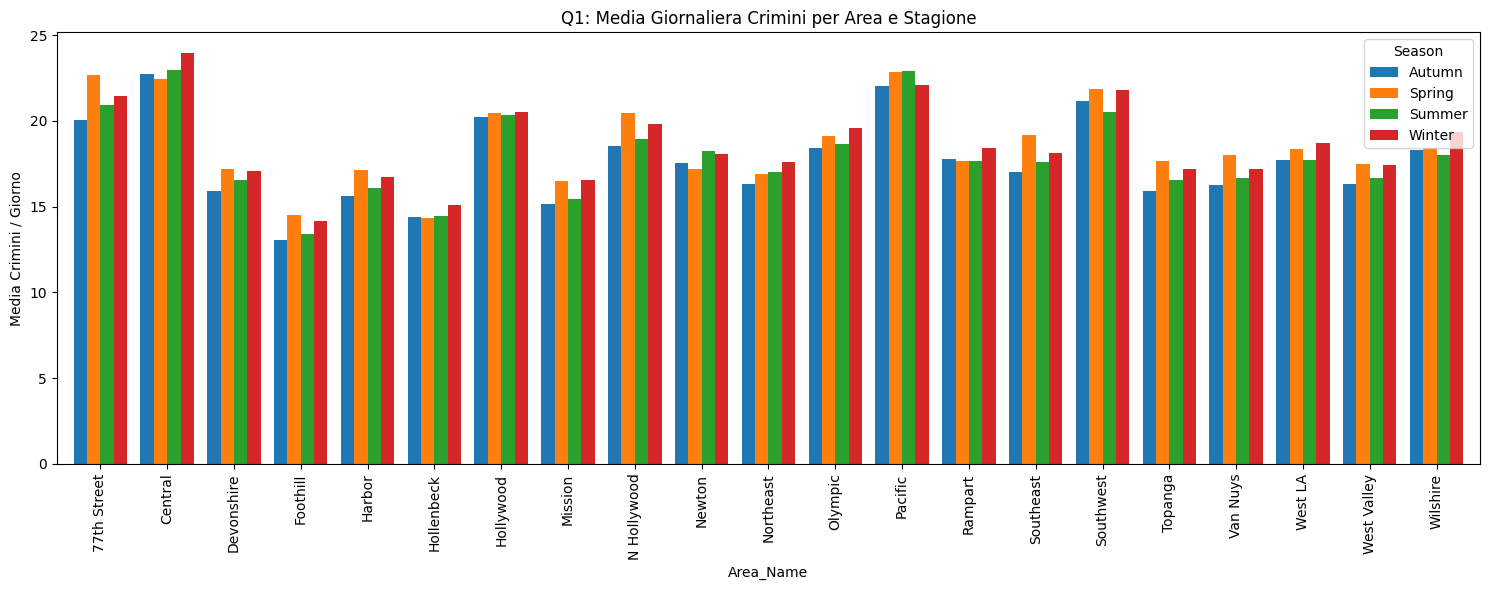

Analisi: Osservare il grafico per identificare le aree con picchi specifici in Estate o Inverno.


In [8]:
# Q1: Numero medio giornaliero di crimini per Area e Stagione [cite: 24]
# Logica: Contiamo i crimini totali per Area/Stagione e dividiamo per una stima dei giorni (5 anni * 90 giorni).
print("Esecuzione Q1: Media crimini giornalieri per Area e Stagione...")

q1 = f'''
from(bucket: "{bucket}")
  |> range(start: 2020-01-01T00:00:00Z, stop: 2025-12-31T23:59:59Z)
  |> filter(fn: (r) => r["_measurement"] == "crimes")
  |> filter(fn: (r) => r["_field"] == "DR_NO")
  |> group(columns: ["Area_Name", "Season"])
  |> count()
'''
result_q1 = query_api.query_data_frame(q1)

if not result_q1.empty:
    # Stima giorni per stagione in 5 anni ~ 450 giorni
    result_q1['daily_avg'] = result_q1['_value'] / 450 
    pivot_q1 = result_q1.pivot(index='Area_Name', columns='Season', values='daily_avg')
    
    pivot_q1.plot(kind='bar', figsize=(15, 6), width=0.8)
    plt.title('Q1: Media Giornaliera Crimini per Area e Stagione')
    plt.ylabel('Media Crimini / Giorno')
    plt.tight_layout()
    plt.show()
    
    # Analisi testuale [cite: 25]
    print("Analisi: Osservare il grafico per identificare le aree con picchi specifici in Estate o Inverno.")

Esecuzione Q2: Distribuzione Day/Night (Luglio 2023)...


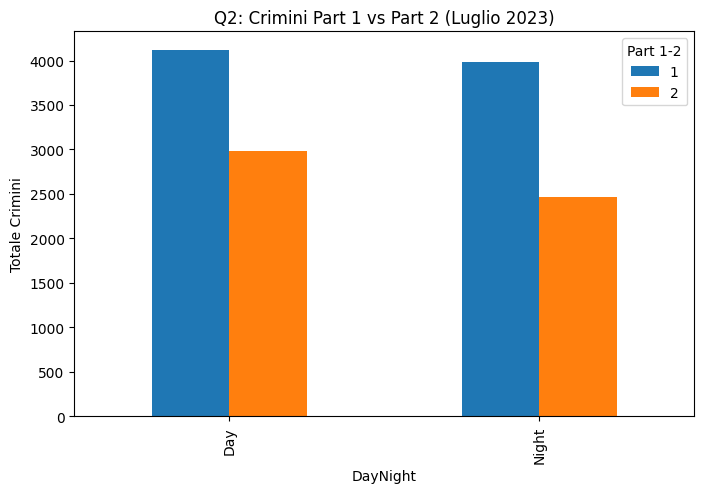

Analisi: Verificare se i crimini gravi (Part 1) sono più frequenti di 'Night'[cite: 27].


In [9]:
# Q2: Distribuzione Part 1 vs Part 2 per Day/Night (Mese: Luglio 2023) [cite: 26]
print("Esecuzione Q2: Distribuzione Day/Night (Luglio 2023)...")

q2 = f'''
from(bucket: "{bucket}")
  |> range(start: 2023-07-01T00:00:00Z, stop: 2023-07-31T23:59:59Z)
  |> filter(fn: (r) => r["_measurement"] == "crimes")
  |> filter(fn: (r) => r["_field"] == "DR_NO")
  |> group(columns: ["Part 1-2", "DayNight"])
  |> count()
'''
result_q2 = query_api.query_data_frame(q2)

if not result_q2.empty:
    pivot_q2 = result_q2.pivot(index='DayNight', columns='Part 1-2', values='_value')
    pivot_q2.plot(kind='bar', figsize=(8, 5))
    plt.title('Q2: Crimini Part 1 vs Part 2 (Luglio 2023)')
    plt.ylabel('Totale Crimini')
    plt.show()
    print("Analisi: Verificare se i crimini gravi (Part 1) sono più frequenti di 'Night'[cite: 27].")

In [12]:
# Q3: Giornata con maggior numero di crimini violenti per Area (CORRETTA)
print("\nEsecuzione Q3: Max crimini violenti giornalieri per Area...")

q3 = f'''
from(bucket: "{bucket}")
  |> range(start: 2020-01-01T00:00:00Z, stop: 2025-12-31T23:59:59Z)
  |> filter(fn: (r) => r["_measurement"] == "crimes")
  |> filter(fn: (r) => r["Part 1-2"] == "1")
  |> filter(fn: (r) => r["_field"] == "DR_NO")
  |> group(columns: ["Area_Name"])
  |> aggregateWindow(every: 1d, fn: count)  // Calcola il conteggio giornaliero e mantiene il _time
  |> max()                                  // Trova il giorno con il valore massimo per ogni Area
'''

try:
    result_q3 = query_api.query_data_frame(q3)
    if not result_q3.empty:
        # Pulizia e visualizzazione
        # Rinominiamo le colonne per chiarezza
        display_q3 = result_q3[['Area_Name', '_time', '_value']].copy()
        display_q3['_time'] = pd.to_datetime(display_q3['_time']).dt.date
        display_q3.columns = ['Area', 'Data del Picco', 'Numero Crimini']
        
        # Ordiniamo per numero di crimini decrescente
        display_q3 = display_q3.sort_values('Numero Crimini', ascending=False)
        
        print(display_q3.head(10))
    else:
        print("Nessun dato trovato per Q3.")
except Exception as e:
    print(f"Errore Q3: {e}")


Esecuzione Q3: Max crimini violenti giornalieri per Area...
Errore Q3: HTTPConnectionPool(host='localhost', port=8086): Read timed out. (read timeout=9.999043541029096)


In [13]:
# Q4: Età media vittime per Categoria e Anno [cite: 30]
print("Esecuzione Q4: Età media vittime...")

q4 = f'''
from(bucket: "{bucket}")
  |> range(start: 2020-01-01T00:00:00Z, stop: 2025-12-31T23:59:59Z)
  |> filter(fn: (r) => r["_measurement"] == "crimes")
  |> filter(fn: (r) => r["_field"] == "Vict_Age")
  |> filter(fn: (r) => r["_value"] > 0)
  |> group(columns: ["Part 1-2"])
  |> window(every: 1y)
  |> mean()
  |> duplicate(column: "_start", as: "Year")
  |> window(every: inf)
'''
result_q4 = query_api.query_data_frame(q4)

if not result_q4.empty:
    result_q4['Year'] = pd.to_datetime(result_q4['Year']).dt.year
    pivot_q4 = result_q4.pivot(index='Year', columns='Part 1-2', values='_value')
    print(pivot_q4)
    pivot_q4.plot(kind='line', marker='o', figsize=(10, 5))
    plt.title('Q4: Età Media Vittime per Anno')
    plt.ylabel('Età Media')
    plt.show()

Esecuzione Q4: Età media vittime...


ApiException: (400)
Reason: Bad Request
HTTP response headers: HTTPHeaderDict({'Content-Type': 'application/json; charset=utf-8', 'Vary': 'Accept-Encoding', 'X-Influxdb-Build': 'OSS', 'X-Influxdb-Version': '2.7.12', 'X-Platform-Error-Code': 'invalid', 'Date': 'Fri, 21 Nov 2025 14:18:26 GMT', 'Transfer-Encoding': 'chunked'})
HTTP response body: b'{"code":"invalid","message":"runtime error @11:6-11:24: window: missing time column \\"_time\\""}'


### Performance Check [cite: 31, 32]
Confrontiamo il tempo di esecuzione di una query globale vs una filtrata per stagione.

In [14]:
def measure_query(season_filter=None):
    base_q = f'''
    from(bucket: "{bucket}")
      |> range(start: 2023-01-01T00:00:00Z, stop: 2023-12-31T23:59:59Z)
      |> filter(fn: (r) => r["_measurement"] == "crimes")
      |> filter(fn: (r) => r["_field"] == "DR_NO")
    '''
    if season_filter:
        base_q += f' |> filter(fn: (r) => r["Season"] == "{season_filter}")'
    
    base_q += ' |> count()'
    
    start = time.time()
    query_api.query(base_q)
    return time.time() - start

t_global = measure_query()
t_seasonal = measure_query("Summer")

print(f"Tempo Query Globale: {t_global:.4f} s")
print(f"Tempo Query Stagionale (Summer): {t_seasonal:.4f} s")
print(f"Miglioramento: {((t_global - t_seasonal)/t_global)*100:.1f}% (Atteso: I tag indicizzati rendono il filtro veloce)")

Tempo Query Globale: 1.8548 s
Tempo Query Stagionale (Summer): 0.2911 s
Miglioramento: 84.3% (Atteso: I tag indicizzati rendono il filtro veloce)


--- 
## 5. Analisi Avanzata: Clustering Incrementale

Utilizziamo `MiniBatchKMeans` per raggruppare le aree in base ai pattern di criminalità aggregati (Area, Stagione, Anno).
Features: Totale Crimini, % Arma, % Notte, % Violenti[cite: 33].

--- Centroidi dei Cluster (Pattern identificati) ---
   Total_Crimes  Weapon_Pct  Night_Pct  Violent_Pct
0   3068.679558    0.274244   0.450618     0.615640
1   3008.212314    0.428716   0.480131     0.582074
2   1130.532646    0.046156   0.461761     0.771965
3   2188.532097    0.303628   0.461960     0.585044

--- Confronto 2020 vs 2025: Evoluzione Cluster [cite: 34] ---
Cluster  0.0  1.0  2.0  3.0
Year                       
2020       4   28    0   52
2021       8   28    0   48
2022      21   26    0   37
2023      22   26    0   36
2024       3    2   47   32
2025       0    4    8   17


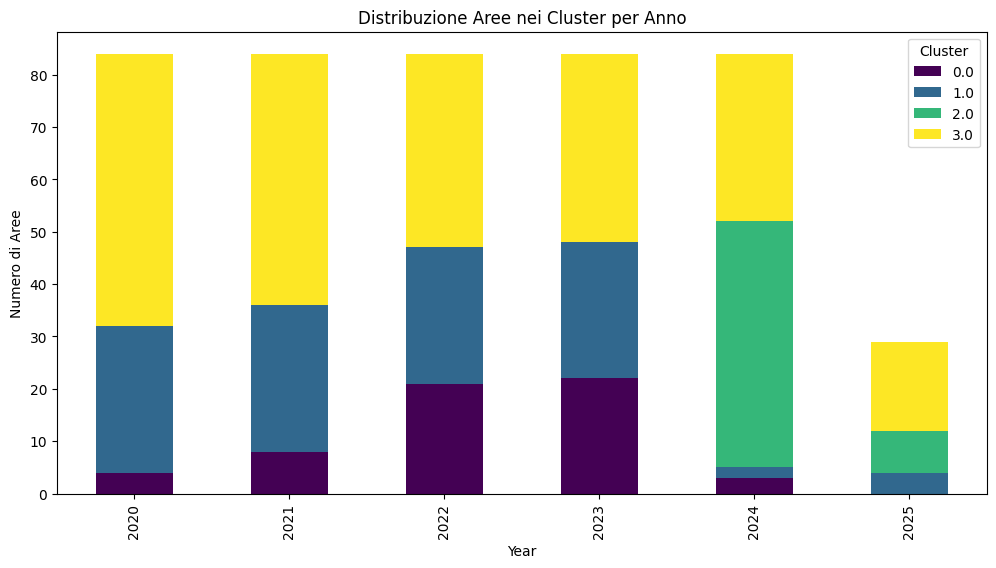

In [15]:
# Aggregazione dati (Dataset Pandas) per preparazione Features
df['Year'] = df['DATE OCC'].dt.year

agg_df = df.groupby(['Area_Name', 'Season', 'Year']).agg(
    Total_Crimes=('DR_NO', 'count'),
    Weapon_Pct=('WeaponFlag', 'mean'),
    Night_Pct=('DayNight', lambda x: (x=='Night').mean()),
    Violent_Pct=('Part 1-2', lambda x: (x=='1').mean())
).reset_index()

features = ['Total_Crimes', 'Weapon_Pct', 'Night_Pct', 'Violent_Pct']
X = agg_df[features]

# Normalizzazione
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Clustering Incrementale (Train su 2020-2024)
train_mask = agg_df['Year'] < 2025
X_train = X_scaled[train_mask]
X_test = X_scaled[~train_mask]

kmeans = MiniBatchKMeans(n_clusters=4, random_state=42, batch_size=256)
kmeans.fit(X_train)

# Assegnazione Cluster
agg_df.loc[train_mask, 'Cluster'] = kmeans.labels_
if len(X_test) > 0:
    agg_df.loc[~train_mask, 'Cluster'] = kmeans.predict(X_test)

# Analisi Risultati
print("--- Centroidi dei Cluster (Pattern identificati) ---")
centroids = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)
print(centroids)

print("\n--- Confronto 2020 vs 2025: Evoluzione Cluster [cite: 34] ---")
cluster_dist = agg_df.groupby(['Year', 'Cluster']).size().unstack(fill_value=0)
print(cluster_dist)

# Visualizzazione
cluster_dist.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='viridis')
plt.title('Distribuzione Aree nei Cluster per Anno')
plt.ylabel('Numero di Aree')
plt.show()